<a href="https://colab.research.google.com/github/Shiku03/Distributed-Telecom-Resource-Management-System/blob/master/Milestone%209%20and%2010.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pyspark

In [2]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("TeleRM Milestones 9 and 10")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

print("Apache Spark initialised successfully")
print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)

Apache Spark initialised successfully
Spark version: 4.0.5
Spark master: local[*]


In [3]:
from google.colab import files

uploaded = files.upload()

Saving TeleRM_All_Experiments.zip to TeleRM_All_Experiments.zip


In [4]:
import os
import zipfile

ZIP_NAME = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

EXTRACT_DIR = "/content/telerm_data"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_NAME, "r") as archive:
    archive.extractall(EXTRACT_DIR)

print("Extraction completed.")

for root, dirs, filenames in os.walk(EXTRACT_DIR):
    print(root, filenames[:10])

Extraction completed.
/content/telerm_data ['failure_run_01\\generator_log.json', 'failure_run_01\\analytics\\events.jsonl', 'high_workload\\name_resolution_log.json', 'high_workload\\analytics\\events.csv', 'failure_run_01\\service_registry_log.json', 'scenario\\replication_log.json', 'scenario\\instances_log.json', 'scenario_sample\\migration_log.json', 'scenario\\generator_log.json', 'edge_first-seed42-20260928-121253\\site-edge-A.log']


In [5]:
import glob

migration_files = glob.glob(
    EXTRACT_DIR + "/**/migration_log.json",
    recursive=True
)

print("Migration log files found:", len(migration_files))

for path in migration_files:
    print(path)

Migration log files found: 0


In [6]:
import os

EXTRACT_DIR = "/content/telerm_data"

print("Does extraction directory exist:", os.path.exists(EXTRACT_DIR))

for root, dirs, filenames in os.walk(EXTRACT_DIR):
    level = root.replace(EXTRACT_DIR, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for filename in filenames:
        print(f"{indent}    {filename}")

Does extraction directory exist: True
telerm_data/
    failure_run_01\generator_log.json
    failure_run_01\analytics\events.jsonl
    high_workload\name_resolution_log.json
    high_workload\analytics\events.csv
    failure_run_01\service_registry_log.json
    scenario\replication_log.json
    scenario\instances_log.json
    scenario_sample\migration_log.json
    scenario\generator_log.json
    edge_first-seed42-20260928-121253\site-edge-A.log
    failure_run_01\performance_metrics.json
    scenario\heartbeat_log.json
    scenario\generator_summary.json
    failure_run_01\site-edge-B.log
    high_workload\service_registry_log.json
    failure_run_02\manager_report.json
    scenario\telerm_control.sqlite3
    edge_first-seed42-20260928-121253\utilisation_timeseries.json
    failure_run_02\site-edge-B.log
    scenario\site-core-1.log
    scenario\telerm_control.sqlite3-wal
    high_workload\migration_log.json
    high_workload\telerm_control.sqlite3-shm
    high_workload\performance_met

In [7]:
import glob

all_json_files = glob.glob(
    "/content/telerm_data/**/*.json",
    recursive=True
)

print("Total JSON files found:", len(all_json_files))

for path in all_json_files:
    print(path)

Total JSON files found: 79
/content/telerm_data/failure_run_01\generator_log.json
/content/telerm_data/high_workload\name_resolution_log.json
/content/telerm_data/failure_run_01\service_registry_log.json
/content/telerm_data/scenario\replication_log.json
/content/telerm_data/scenario\instances_log.json
/content/telerm_data/scenario_sample\migration_log.json
/content/telerm_data/scenario\generator_log.json
/content/telerm_data/failure_run_01\performance_metrics.json
/content/telerm_data/scenario\heartbeat_log.json
/content/telerm_data/scenario\generator_summary.json
/content/telerm_data/high_workload\service_registry_log.json
/content/telerm_data/failure_run_02\manager_report.json
/content/telerm_data/edge_first-seed42-20260928-121253\utilisation_timeseries.json
/content/telerm_data/high_workload\migration_log.json
/content/telerm_data/high_workload\performance_metrics.json
/content/telerm_data/high_workload\process_lifecycle_log.json
/content/telerm_data/high_workload\failure_events.js

In [8]:
import os
import shutil

EXTRACT_DIR = "/content/telerm_data"

repaired = 0

for root, dirs, filenames in os.walk(EXTRACT_DIR):
    for filename in filenames:

        if "\\" not in filename:
            continue

        source = os.path.join(root, filename)

        # Convert Windows-style path separators into Linux directories
        parts = filename.split("\\")
        destination = os.path.join(root, *parts)

        os.makedirs(os.path.dirname(destination), exist_ok=True)

        shutil.move(source, destination)
        repaired += 1

print("Path repairs completed:", repaired)

Path repairs completed: 121


In [9]:
import os

for root, dirs, filenames in os.walk(EXTRACT_DIR):
    level = root.replace(EXTRACT_DIR, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for filename in sorted(filenames):
        print(f"{indent}    {filename}")

telerm_data/
    failure_run_01/
        failure_events.json
        generator_log.json
        generator_summary.json
        heartbeat_log.json
        instances_log.json
        manager.log
        manager_report.json
        migration_log.json
        name_resolution_log.json
        performance_metrics.json
        process_lifecycle_log.json
        recovery_log.json
        replication_log.json
        scenario_config.json
        scenario_report.json
        service_registry_log.json
        site-core-1.log
        site-edge-A.log
        site-edge-B.log
        telerm_control.sqlite3
        telerm_control.sqlite3-shm
        telerm_control.sqlite3-wal
        utilisation_timeseries.json
        analytics/
            events.csv
            events.jsonl
            operations.csv
    high_workload/
        failure_events.json
        generator_log.json
        generator_summary.json
        heartbeat_log.json
        instances_log.json
        manager_report.json
        migrat

In [10]:
import glob

migration_files = glob.glob(
    EXTRACT_DIR + "/**/migration_log.json",
    recursive=True
)

print("Migration log files found:", len(migration_files))

for path in sorted(migration_files):
    print(path)

Migration log files found: 5
/content/telerm_data/failure_run_01/migration_log.json
/content/telerm_data/failure_run_02/migration_log.json
/content/telerm_data/high_workload/migration_log.json
/content/telerm_data/scenario/migration_log.json
/content/telerm_data/scenario_sample/migration_log.json


In [11]:
baseline_migration = (
    EXTRACT_DIR + "/scenario/migration_log.json"
)

migration_df = (
    spark.read
    .option("multiLine", "true")
    .json(baseline_migration)
)

migration_df.printSchema()
migration_df.show(10, truncate=False)

root
 |-- events: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- destination: string (nullable = true)
 |    |    |-- downtime_s: double (nullable = true)
 |    |    |-- duration_s: double (nullable = true)
 |    |    |-- event: string (nullable = true)
 |    |    |-- generation: long (nullable = true)
 |    |    |-- instance_id: string (nullable = true)
 |    |    |-- logical_name: string (nullable = true)
 |    |    |-- operation_id: string (nullable = true)
 |    |    |-- path: array (nullable = true)
 |    |    |    |-- element: string (containsNull = true)
 |    |    |-- site_id: string (nullable = true)
 |    |    |-- source: string (nullable = true)
 |    |    |-- source_released: boolean (nullable = true)
 |    |    |-- ts: double (nullable = true)
 |-- operations: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- instance_id: string (nullable = true)
 |    |    |-- operation_id: string (nullable = tru

In [12]:
from pyspark.sql import functions as F

migration_operations_df = (
    migration_df
    .select(F.explode("operations").alias("op"))
    .select(
        F.col("op.operation_id").alias("operation_id"),
        F.col("op.instance_id").alias("instance_id"),
        F.col("op.operation_type").alias("operation_type"),
        F.col("op.state").alias("state"),
        F.col("op.source_site").alias("source_site"),
        F.col("op.target_site").alias("target_site"),
        F.col("op.payload.duration_s").alias("duration_s"),
        F.col("op.payload.downtime_s").alias("downtime_s"),
        F.col("op.payload.old_generation").alias("old_generation"),
        F.col("op.payload.new_generation").alias("new_generation"),
        F.col("op.payload.source_released").alias("source_released"),
        F.col("op.payload.reason").alias("reason")
    )
)

migration_operations_df.show(truncate=False)
migration_operations_df.printSchema()

+----------------+-----------+--------------+---------+-----------+-----------+--------------------+--------------------+--------------+--------------+---------------+---------+
|operation_id    |instance_id|operation_type|state    |source_site|target_site|duration_s          |downtime_s          |old_generation|new_generation|source_released|reason   |
+----------------+-----------+--------------+---------+-----------+-----------+--------------------+--------------------+--------------+--------------+---------------+---------+
|mig-1734a2b5aa8e|S00017     |MIGRATION     |COMMITTED|edge-A     |core-1     |0.033785343170166016|0.02555251121520996 |1             |2             |true           |requested|
|mig-ac0606c0bf52|S00020     |MIGRATION     |COMMITTED|edge-B     |core-1     |0.009766817092895508|0.007582426071166992|1             |2             |true           |requested|
+----------------+-----------+--------------+---------+-----------+-----------+--------------------+----------

In [13]:
migration_summary = migration_operations_df.agg(
    F.count("*").alias("total_migrations"),

    F.sum(
        F.when(F.col("state") == "COMMITTED", 1).otherwise(0)
    ).alias("successful_migrations"),

    F.round(
        F.avg("duration_s") * 1000, 3
    ).alias("mean_duration_ms"),

    F.round(
        F.avg("downtime_s") * 1000, 3
    ).alias("mean_downtime_ms"),

    F.round(
        F.max("duration_s") * 1000, 3
    ).alias("maximum_duration_ms"),

    F.sum(
        F.when(F.col("source_released") == True, 1).otherwise(0)
    ).alias("source_releases_confirmed")
)

migration_summary.show(truncate=False)

+----------------+---------------------+----------------+----------------+-------------------+-------------------------+
|total_migrations|successful_migrations|mean_duration_ms|mean_downtime_ms|maximum_duration_ms|source_releases_confirmed|
+----------------+---------------------+----------------+----------------+-------------------+-------------------------+
|2               |2                    |21.776          |16.567          |33.785             |2                        |
+----------------+---------------------+----------------+----------------+-------------------+-------------------------+



In [18]:
migration_events_df = (
    migration_df
    .select(F.explode("events").alias("event"))
    .select(
        F.col("event.operation_id").alias("operation_id"),
        F.col("event.instance_id").alias("instance_id"),
        F.col("event.event").alias("event_type"),
        F.col("event.source").alias("source_site"),
        F.col("event.destination").alias("destination_site"),
        F.col("event.ts").alias("timestamp"),
        F.col("event.duration_s").alias("duration_s"),
        F.col("event.downtime_s").alias("downtime_s")
    )
)

migration_events_df.groupBy("event_type").count().orderBy(
    "event_type"
).show(truncate=False)



+------------------------+-----+
|event_type              |count|
+------------------------+-----+
|MIGRATION_COMMITTED     |2    |
|MIGRATION_COMMIT_DECIDED|2    |
|MIGRATION_STARTED       |2    |
+------------------------+-----+



In [20]:
from pyspark.sql import functions as F
import glob

migration_files = sorted(
    glob.glob(
        EXTRACT_DIR + "/**/migration_log.json",
        recursive=True
    )
)

print("Migration files:", len(migration_files))

all_migration_logs = (
    spark.read
    .option("multiLine", "true")
    .json(migration_files)
    .withColumn("source_file", F.input_file_name())
    .withColumn(
        "experiment",
        F.regexp_extract(
            F.input_file_name(),
            r"/([^/]+)/migration_log\.json$",
            1
        )
    )
)

all_migration_operations = (
    all_migration_logs
    .select(
        "experiment",
        F.explode("operations").alias("op")
    )
    .select(
        "experiment",
        F.col("op.operation_id").alias("operation_id"),
        F.col("op.state").alias("state"),
        F.col("op.source_site").alias("source_site"),
        F.col("op.target_site").alias("target_site"),
        F.col("op.payload.duration_s").alias("duration_s"),
        F.col("op.payload.downtime_s").alias("downtime_s"),
        F.col("op.payload.source_released").alias("source_released")
    )
)

migration_comparison = (
    all_migration_operations
    .groupBy("experiment")
    .agg(
        F.count("*").alias("total_migrations"),
        F.sum(
            F.when(F.col("state") == "COMMITTED", 1).otherwise(0)
        ).alias("successful_migrations"),
        F.round(F.avg("duration_s") * 1000, 3).alias("mean_duration_ms"),
        F.round(F.avg("downtime_s") * 1000, 3).alias("mean_downtime_ms"),
        F.sum(
            F.when(F.col("source_released") == True, 1).otherwise(0)
        ).alias("confirmed_source_releases")
    )
    .orderBy("experiment")
)

migration_comparison.show(truncate=False)

Migration files: 5
+---------------+----------------+---------------------+----------------+----------------+-------------------------+
|experiment     |total_migrations|successful_migrations|mean_duration_ms|mean_downtime_ms|confirmed_source_releases|
+---------------+----------------+---------------------+----------------+----------------+-------------------------+
|failure_run_01 |2               |2                    |21.043          |18.102          |2                        |
|failure_run_02 |2               |2                    |20.958          |18.847          |2                        |
|scenario       |2               |2                    |21.776          |16.567          |2                        |
|scenario_sample|2               |2                    |5.39            |4.719           |2                        |
+---------------+----------------+---------------------+----------------+----------------+-------------------------+



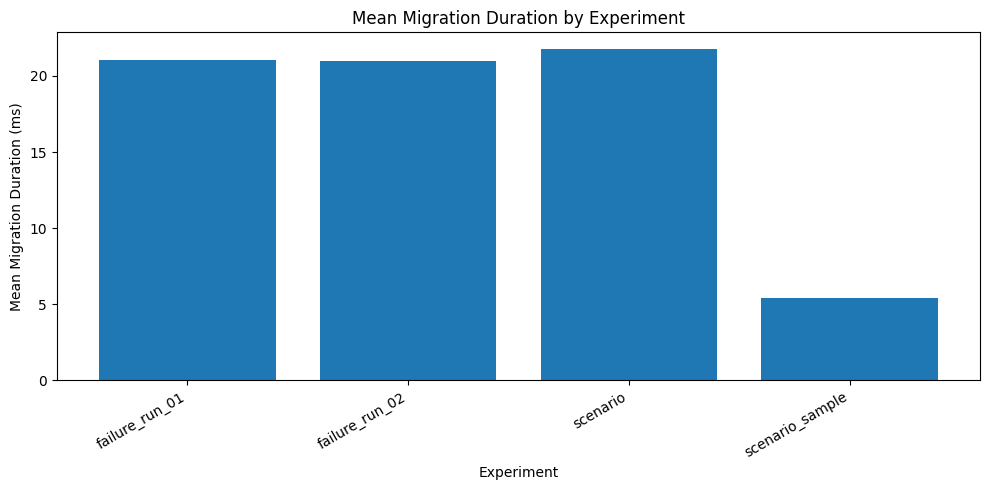

In [21]:
import matplotlib.pyplot as plt

migration_plot = migration_comparison.toPandas()

plt.figure(figsize=(10, 5))
plt.bar(
    migration_plot["experiment"],
    migration_plot["mean_duration_ms"]
)

plt.title("Mean Migration Duration by Experiment")
plt.xlabel("Experiment")
plt.ylabel("Mean Migration Duration (ms)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()